# 02 การตรวจจับน้ำท่วมด้วย change detection และ threshold

**ชุดการสอน:** Teach_SAR_flood_Mapping_ML | **เวลาโดยประมาณ:** 120 นาที | **ต้องทำก่อน:** `01`

## จุดประสงค์
เมื่อจบ notebook นี้ นิสิตจะสามารถ
1. กรอง speckle อย่างถูกหลัก (บนค่า linear) และอธิบายผลของขนาดหน้าต่าง
2. สร้างภาพความต่างของสองช่วงเวลา และ **หา threshold ที่เหมาะสมด้วยตนเอง**
3. ใช้วิธี Otsu หา threshold อัตโนมัติ และบอกได้ว่าเมื่อใดใช้ไม่ได้
4. ปรับแต่งผลด้วยข้อมูลน้ำถาวร ความลาดชัน และขนาดกลุ่มจุดภาพ

วิธีการดัดแปลงจาก UN-SPIDER Recommended Practice

## 0. เตรียมสภาพแวดล้อม
เซลล์นี้ดาวน์โหลดข้อมูลและฟังก์ชันกลาง (`sarflood_utils.py`) จาก GitHub ของรายวิชา **notebook นี้ไม่ต้องใช้ Google Earth Engine** เพราะข้อมูลถูกเตรียมไว้แล้วใน `00`

รูปทุกรูปใช้ป้ายกำกับภาษาอังกฤษ เพราะเป็นมาตรฐานของวารสารนานาชาติ และ Colab ไม่มีฟอนต์ไทยสำหรับ matplotlib

In [1]:
!pip -q install rasterio

import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = 'Teach_SAR_flood_Mapping_ML'
if not os.path.isdir(REPO):
    !git clone -q --depth 1 https://github.com/nattaponm/{REPO}.git
sys.path.insert(0, REPO)
import sarflood_utils as su

DATA = f'{REPO}/data'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9})
print('ไฟล์ข้อมูล:', sorted(os.listdir(DATA)))

ไฟล์ข้อมูล: ['S1_20171017_VH.tif', 'S1_20171017_VV.tif', 'S1_20180109_VH.tif', 'S1_20180109_VV.tif', 'boundary_amphoe.geojson', 'boundary_province.geojson', 'dem_srtm.tif', 'ghsl_pop_2020.tif', 'jrc_seasonality.tif', 'readme.txt', 'slope_srtm.tif', 'worldcover_2020.tif']


In [2]:
ref_raw, grid = su.load_s1(DATA, su.REF_TAG, 'VH')      # ภาพอ้างอิง
fld_raw, _    = su.load_s1(DATA, su.FLOOD_TAG, 'VH')    # ภาพน้ำท่วม
amphoe, province = su.load_boundaries(DATA, grid['crs'])
px_rai = su.pixel_area_m2(grid) / su.RAI_M2             # พื้นที่ของหนึ่งจุดภาพ หน่วยไร่
print(f'หนึ่งจุดภาพ = {su.pixel_area_m2(grid):.0f} ตร.ม. = {px_rai:.4f} ไร่')

หนึ่งจุดภาพ = 100 ตร.ม. = 0.0625 ไร่


## 1. กรอง speckle

Speckle คือสัญญาณรบกวนลักษณะเม็ดเกลือพริกไทย เกิดจากการแทรกสอดของคลื่นที่สะท้อนจากวัตถุย่อยจำนวนมากในจุดภาพเดียว ถ้าไม่กรอง แผนที่น้ำท่วมจะเต็มไปด้วยจุดเล็ก ๆ

ตัวกรองที่ง่ายที่สุดคือค่าเฉลี่ยเคลื่อนที่ (boxcar) ขนาด $n \times n$ จุดภาพ ซึ่งต้องทำบนค่า linear

$$\hat\sigma^0 = \frac{1}{n^2}\sum_{i=1}^{n^2}\sigma^0_i$$

หน้าต่างใหญ่ขึ้นภาพเรียบขึ้น แต่ขอบของวัตถุจะเบลอ เราใช้ $n = 7$ (70 ม.) ซึ่งใกล้เคียงรัศมี 50 ม. ในโค้ดต้นแบบ

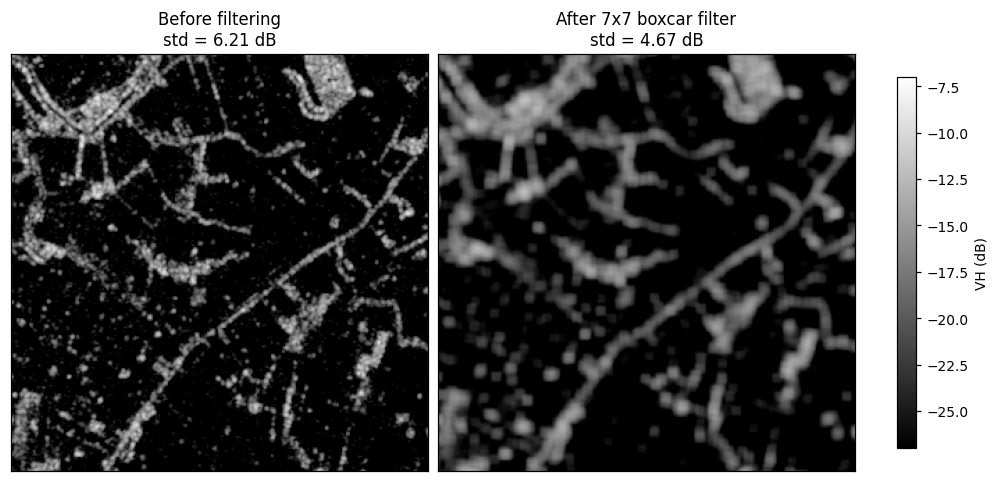

In [3]:
SIZE = 7
ref = su.speckle_filter(ref_raw, SIZE)
fld = su.speckle_filter(fld_raw, SIZE)

# ขยายดูบริเวณกลางภาพ 300 x 300 จุดภาพ
r0, c0 = grid['height'] // 2 - 150, grid['width'] // 2 - 150
win = (slice(r0, r0 + 300), slice(c0, c0 + 300))
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5), constrained_layout=True)
for ax, a, title in zip(axes, [fld_raw, fld], ['Before filtering', f'After {SIZE}x{SIZE} boxcar filter']):
    im = ax.imshow(a[win], cmap='gray', vmin=-27, vmax=-7)
    ax.set_title(f'{title}\nstd = {np.nanstd(a[win]):.2f} dB'); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=0.8, label='VH (dB)')
plt.show()

## 2. ภาพความต่าง (change detection)

$$\Delta\sigma^0_{dB} = \sigma^0_{flood,\,dB} - \sigma^0_{ref,\,dB} = 10\log_{10}\!\left(\frac{\sigma^0_{flood}}{\sigma^0_{ref}}\right)$$

ผลต่างใน dB เท่ากับอัตราส่วนในหน่วย linear ค่าที่ **ติดลบมาก** หมายถึง backscatter ลดลงมาก ซึ่งเป็นลักษณะของพื้นที่ที่เปลี่ยนจากแห้งเป็นมีน้ำ

> **เทียบกับโค้ดต้นแบบ (JavaScript):** ต้นแบบใช้ `after.divide(before)` บนค่า dB โดยตรงแล้วตัดที่ 1.25 ซึ่งใช้ได้ผลเพราะค่า dB ทั้งคู่ติดลบ เช่น −20 / −16 = 1.25 แต่อัตราส่วนของ dB ไม่มีความหมายทางฟิสิกส์ และค่าเดียวกันให้ผลไม่เท่ากันในแต่ละระดับความสว่าง เช่น ที่ภาพอ้างอิง −16 dB เทียบเท่าผลต่าง −4 dB แต่ที่ −12 dB เทียบเท่าผลต่างเพียง −3 dB เราจึงใช้ผลต่างใน dB แทน

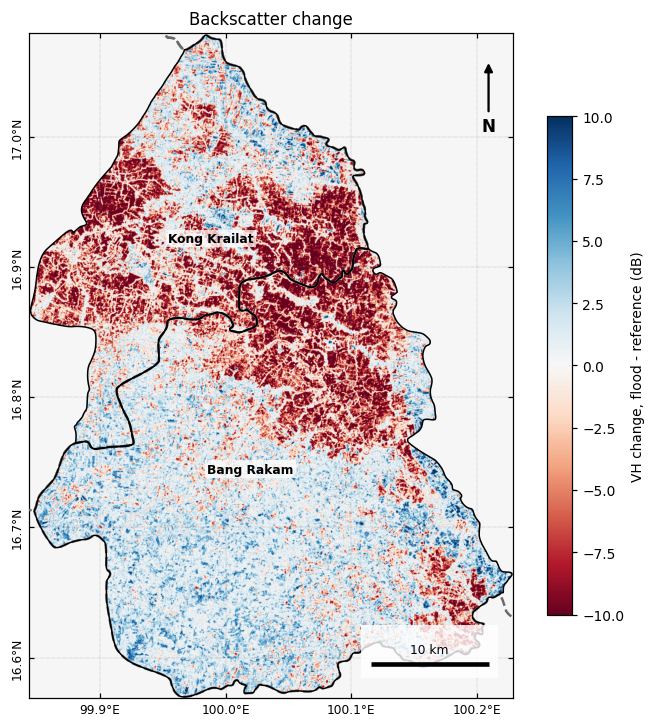

In [4]:
diff = fld - ref
valid = np.isfinite(diff)

fig, ax = plt.subplots(figsize=(7.5, 6.5), constrained_layout=True)
im = ax.imshow(diff, cmap='RdBu', vmin=-10, vmax=10, extent=su.extent(grid))
su.journal_map(ax, grid, amphoe, province)
fig.colorbar(im, ax=ax, shrink=0.75, label='VH change, flood - reference (dB)')
ax.set_title('Backscatter change')
plt.show()

## 3. หา threshold ด้วยตนเอง

ขั้นตอนนี้สำคัญที่สุดของบทเรียน เพราะ **ไม่มีค่า threshold สากล** แต่ละพื้นที่และเหตุการณ์ต้องหาเอง

**3.1 ดู histogram** ถ้ามีพื้นที่น้ำท่วมมากพอ จะเห็นยอดหรือไหล่ทางซ้ายแยกจากยอดหลักใกล้ 0 dB ค่า threshold ที่ดีอยู่ในหุบระหว่างสองยอด

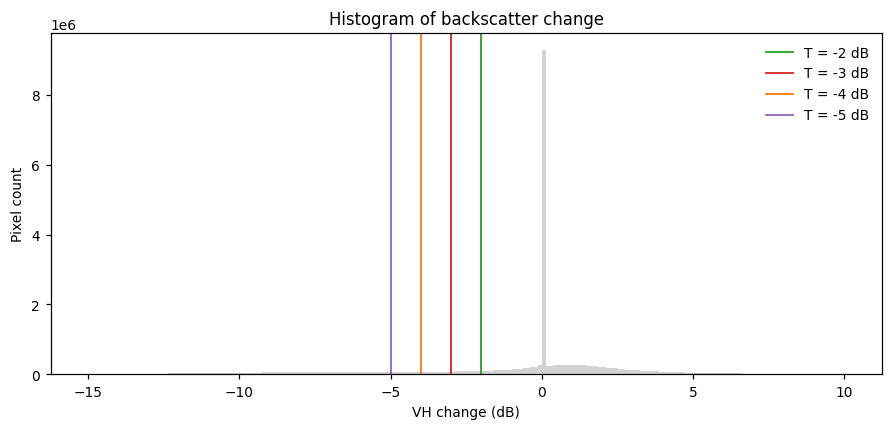

In [5]:
candidates = [-2.0, -3.0, -4.0, -5.0]
d = diff[valid]

fig, ax = plt.subplots(figsize=(8, 3.8), constrained_layout=True)
ax.hist(d, bins=np.linspace(-15, 10, 201), color='lightgray', edgecolor='none')
for t, c in zip(candidates, ['tab:green', 'tab:red', 'tab:orange', 'tab:purple']):
    ax.axvline(t, color=c, linewidth=1.2, label=f'T = {t:.0f} dB')
ax.set_xlabel('VH change (dB)'); ax.set_ylabel('Pixel count'); ax.legend(frameon=False)
ax.set_title('Histogram of backscatter change')
plt.show()

**3.2 ความไวของพื้นที่ต่อ threshold** พื้นที่น้ำท่วมคำนวณจาก

$$A_{rai} = \frac{N_{flood}\times a_{pixel}}{1{,}600}$$

โดย $a_{pixel}$ คือพื้นที่หนึ่งจุดภาพ (ตร.ม.) และ 1 ไร่ = 1,600 ตร.ม. ถ้ากราฟชันมากรอบค่าที่เลือก แสดงว่าผลลัพธ์ไวต่อการเลือก threshold และต้องรายงานความไม่แน่นอนนี้

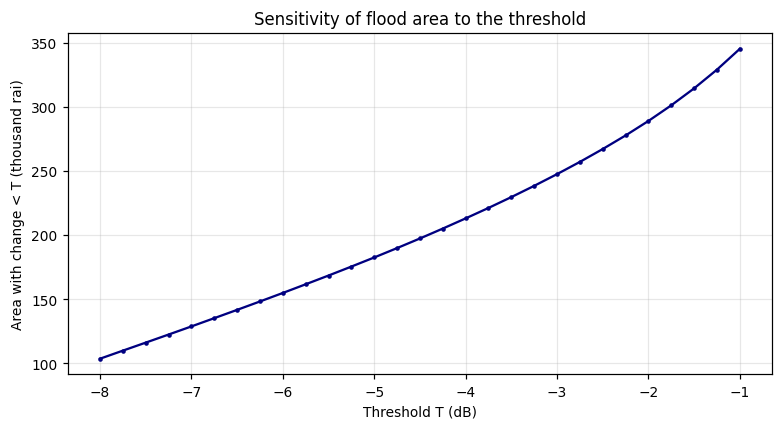

,T (dB),พื้นที่ (ไร่),ร้อยละของพื้นที่ศึกษา
0,-2.0,288995,20.0
1,-3.0,247527,17.1
2,-4.0,213024,14.7
3,-5.0,182555,12.6


In [6]:
ts = np.arange(-8, -0.9, 0.25)
area = np.array([(d < t).sum() * px_rai for t in ts])

fig, ax = plt.subplots(figsize=(7, 3.8), constrained_layout=True)
ax.plot(ts, area / 1000, color='navy', marker='.', markersize=4)
ax.set_xlabel('Threshold T (dB)'); ax.set_ylabel('Area with change < T (thousand rai)')
ax.grid(alpha=0.3); ax.set_title('Sensitivity of flood area to the threshold')
plt.show()

pd.DataFrame({'T (dB)': candidates,
              'พื้นที่ (ไร่)': [round((d < t).sum() * px_rai) for t in candidates],
              'ร้อยละของพื้นที่ศึกษา': [round(100 * (d < t).mean(), 1) for t in candidates]})

**3.3 วิธี Otsu** เลือก threshold $t$ ที่ทำให้ความแปรปรวนระหว่างสองกลุ่มสูงสุด

$$t^* = \arg\max_t\; \omega_0(t)\,\omega_1(t)\,\big[\mu_0(t)-\mu_1(t)\big]^2$$

โดย $\omega_0,\omega_1$ คือสัดส่วนจุดภาพของกลุ่มที่อยู่ต่ำกว่าและสูงกว่า $t$ และ $\mu_0,\mu_1$ คือค่าเฉลี่ยของแต่ละกลุ่ม วิธีนี้ทำงานดีเมื่อ histogram มีสองยอดชัดเจนและสองกลุ่มมีขนาดไม่ต่างกันมาก

In [7]:
from skimage.filters import threshold_otsu

sample = np.random.default_rng(0).choice(d, size=min(d.size, 1_000_000), replace=False)
t_otsu = float(threshold_otsu(sample[(sample > -15) & (sample < 10)]))
print(f'Otsu threshold = {t_otsu:.2f} dB  ->  {(d < t_otsu).sum() * px_rai:,.0f} ไร่')

Otsu threshold = -3.72 dB  ->  222,128 ไร่


**3.4 ตรวจด้วยสายตา** เทียบหน้ากาก (mask) ของแต่ละ threshold กับภาพผสมสองช่วงเวลาจาก `01` บริเวณสีแดงในภาพผสมควรถูกจับได้ครบ โดยไม่กินเข้าไปในพื้นที่สีเทา

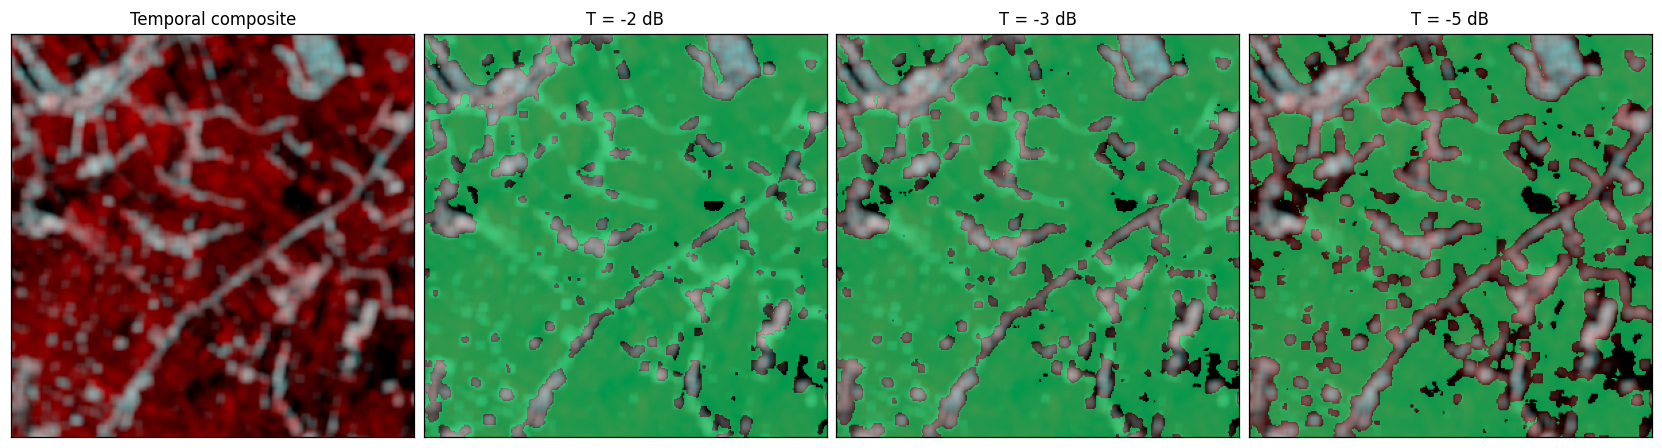

In [8]:
rgb = np.dstack([su.stretch(ref, -27, -7), su.stretch(fld, -27, -7), su.stretch(fld, -27, -7)])
show = [None, -2.0, -3.0, -5.0]
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2), constrained_layout=True)
for ax, t in zip(axes, show):
    ax.imshow(rgb[win])
    if t is None:
        ax.set_title('Temporal composite')
    else:
        m = np.ma.masked_where(~(diff[win] < t), np.ones_like(diff[win]))
        ax.imshow(m, cmap='winter', alpha=0.6, vmin=0, vmax=1)
        ax.set_title(f'T = {t:.0f} dB')
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

**3.5 ตัดสินใจ** กำหนดค่า `T` จากหลักฐานทั้งสี่ข้อข้างต้น ค่าเริ่มต้นของรายวิชาคือ −3 dB (พลังงานลดลงเหลือครึ่งหนึ่ง) นิสิตเปลี่ยนค่านี้ได้ แล้วสังเกตว่าผลใน `03` เปลี่ยนตามอย่างไร

> **ข้อจำกัดสำคัญ:** เรากำลังเลือก threshold โดยไม่มีข้อมูลอ้างอิงภาคสนาม ในงานวิจัยจริงต้องตรวจสอบกับจุดสำรวจ ภาพถ่ายความละเอียดสูงที่แปลด้วยสายตา หรือแผนที่น้ำท่วมจากหน่วยงาน เช่น GISTDA

In [9]:
T = su.DIFF_THRESHOLD        # นิสิตเปลี่ยนเป็นค่าที่ตนเองเลือกได้ เช่น T = t_otsu
raw = valid & (diff < T)
print(f'T = {T} dB  ->  พื้นที่ก่อนปรับแต่ง {raw.sum() * px_rai:,.0f} ไร่')

T = -3.0 dB  ->  พื้นที่ก่อนปรับแต่ง 247,527 ไร่


## 4. ปรับแต่งผลลัพธ์
หน้ากากดิบยังมีสิ่งที่ไม่ใช่น้ำท่วมปนอยู่ จึงตัดออก 3 ขั้น

| ขั้น | เงื่อนไข | เหตุผล |
|---|---|---|
| 1 | ตัดจุดภาพที่ JRC ระบุว่ามีน้ำตั้งแต่ 10 เดือนต่อปีขึ้นไป | เป็นแหล่งน้ำถาวร ไม่ใช่น้ำท่วม |
| 2 | ตัดจุดภาพที่ความลาดชันตั้งแต่ 5 องศาขึ้นไป | น้ำไม่ขังบนที่ลาดชัน และเงาเรดาร์บนภูเขาดูมืดคล้ายน้ำ |
| 3 | ตัดกลุ่มจุดภาพที่ต่อเนื่องกันน้อยกว่า 8 จุดภาพ | ลด speckle ที่หลงเหลือ |

In [10]:
season = su.read_on_grid(f'{DATA}/jrc_seasonality.tif', grid, 'nearest')
slope  = su.read_on_grid(f'{DATA}/slope_srtm.tif', grid, 'bilinear', scale=0.01)   # องศา

perm  = np.nan_to_num(season, nan=0) >= 10
step1 = raw & ~perm
step2 = step1 & (np.nan_to_num(slope, nan=0) < 5)
flood = su.clean_mask(step2, min_pixels=8)

steps = pd.DataFrame({'ขั้นตอน': ['หน้ากากดิบ', 'ตัดน้ำถาวร', 'ตัดความลาดชัน >= 5 องศา', 'ตัดกลุ่ม < 8 จุดภาพ'],
                      'พื้นที่ (ไร่)': [round(m.sum() * px_rai) for m in [raw, step1, step2, flood]]})
steps['เปลี่ยนแปลง (ไร่)'] = steps['พื้นที่ (ไร่)'].diff().fillna(0).astype(int)
steps

,ขั้นตอน,พื้นที่ (ไร่),เปลี่ยนแปลง (ไร่)
0,หน้ากากดิบ,247527,0
1,ตัดน้ำถาวร,247497,-30
2,ตัดความลาดชัน >= 5 องศา,246394,-1103
3,ตัดกลุ่ม < 8 จุดภาพ,245971,-423


ขั้นตอนทั้งหมดถูกรวมไว้ในฟังก์ชัน `su.flood_change_map()` เพื่อให้ notebook ถัดไปเรียกใช้ได้ในบรรทัดเดียว เซลล์ถัดไปตรวจว่าฟังก์ชันให้ผลตรงกับที่เราทำทีละขั้น

In [11]:
fm = su.flood_change_map(DATA, threshold=T)
assert np.array_equal(fm['flood'], flood), 'ผลจากฟังก์ชันไม่ตรงกับที่คำนวณทีละขั้น'
print('ตรงกัน: su.flood_change_map() ให้ผลเหมือนที่คำนวณทีละขั้น')

ตรงกัน: su.flood_change_map() ให้ผลเหมือนที่คำนวณทีละขั้น


## 5. แผนที่น้ำท่วม

บันทึก: outputs/fig02_flood_extent.png


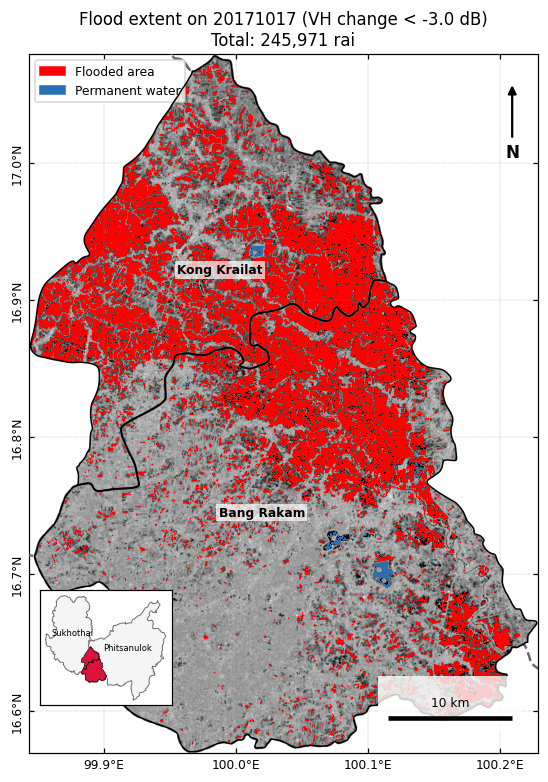

บันทึก: outputs/flood_threshold.tif (1 = ท่วม, 0 = ไม่ท่วม, 255 = ไม่มีข้อมูล)


In [12]:
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(8, 7), constrained_layout=True)
ax.imshow(fld, cmap='gray', vmin=-27, vmax=-7, extent=su.extent(grid))
su.show_mask(ax, perm, grid, '#2a6fb0')
su.show_mask(ax, flood, grid, 'red')
su.journal_map(ax, grid, amphoe, province)
su.add_inset(ax, amphoe, province)
ax.legend(handles=[Patch(color='red', label='Flooded area'), Patch(color='#2a6fb0', label='Permanent water')],
          loc='upper left', frameon=True, fontsize=8)
ax.set_title(f'Flood extent on {su.FLOOD_TAG} (VH change < {T} dB)\nTotal: {flood.sum() * px_rai:,.0f} rai')
su.save_fig(fig, 'fig02_flood_extent.png')
plt.show()

out = np.where(valid, flood.astype('uint8'), 255)
su.write_geotiff('outputs/flood_threshold.tif', out, grid)
print('บันทึก: outputs/flood_threshold.tif (1 = ท่วม, 0 = ไม่ท่วม, 255 = ไม่มีข้อมูล)')

## 6. แบบฝึกหัด

### ข้อ 1 ขนาดหน้าต่างของตัวกรอง
เปลี่ยน `SIZE` เป็น 3 และ 11 แล้วรันใหม่ พื้นที่น้ำท่วมสุดท้ายเปลี่ยนไปอย่างไร และรูปร่างของพื้นที่น้ำท่วมต่างกันอย่างไร

<details><summary><b>เฉลย</b></summary>

```python
for s in [3, 7, 11]:
    m = su.flood_change_map(DATA, threshold=T, filter_size=s)['flood']
    print(s, f'{m.sum() * px_rai:,.0f} ไร่')
```
หน้าต่างเล็กเหลือ speckle มาก ขอบเขตน้ำท่วมจึงขรุขระและมีรูพรุน ส่วนหน้าต่างใหญ่ให้ผลเรียบ แต่แปลงน้ำท่วมขนาดเล็กและแนวแคบ ๆ เช่น คลอง จะหายไป ไม่มีขนาดที่ถูกที่สุด ต้องเลือกให้เหมาะกับขนาดวัตถุที่สนใจ
</details>

### ข้อ 2 ความไม่แน่นอนจาก threshold
ถ้าเลือก T = −2 dB กับ T = −4 dB พื้นที่น้ำท่วมสุดท้าย (หลังปรับแต่ง) ต่างกันกี่ไร่ คิดเป็นร้อยละเท่าไรของค่าที่ T = −3 dB ควรรายงานผลอย่างไรในงานวิจัย

<details><summary><b>เฉลย</b></summary>

```python
a = {t: su.flood_change_map(DATA, threshold=t)['flood'].sum() * px_rai for t in [-2, -3, -4]}
print(a, f"ช่วงกว้าง = {100 * (a[-2] - a[-4]) / a[-3]:.1f}% ของค่าที่ -3 dB")
```
ควรรายงานเป็นช่วง เช่น "พื้นที่น้ำท่วม X ไร่ (ช่วง Y ถึง Z ไร่ เมื่อ threshold อยู่ระหว่าง −4 ถึง −2 dB)" แทนการรายงานตัวเลขเดียว เพราะผู้อ่านจะเห็นว่าผลไวต่อสมมติฐานเพียงใด
</details>

### ข้อ 3 Otsu ใช้ได้เมื่อใด
ค่า Otsu ที่ได้ใกล้กับค่าที่นิสิตเลือกด้วยสายตาหรือไม่ ดูจาก histogram แล้วอธิบายว่าเพราะอะไร

<details><summary><b>เฉลย</b></summary>

ถ้า histogram ของภาพความต่างมีสองยอดชัดเจน Otsu จะให้ค่าในหุบระหว่างยอด ซึ่งมักใกล้กับค่าที่เลือกด้วยตา ถ้าพื้นที่น้ำท่วมมีสัดส่วนน้อย histogram จะมียอดเดียวที่มีหางยาว Otsu จะให้ค่าเอียงเข้าหายอดหลักและตรวจเกิน ทางแก้ที่ใช้กันคือคำนวณ Otsu เฉพาะในบล็อกย่อยที่มีทั้งน้ำและแผ่นดิน (tile-based thresholding)
</details>

### ข้อ 4 น้ำท่วมที่ตรวจไม่พบ
วิธีนี้จับเฉพาะพื้นที่ที่ backscatter **ลดลง** มีน้ำท่วมแบบใดบ้างที่วิธีนี้มองไม่เห็น

<details><summary><b>เฉลย</b></summary>

- **น้ำท่วมใต้พืชหรือในเขตอาคาร:** เกิด double bounce ทำให้ภาพสว่างขึ้น
- **พื้นที่ที่มีน้ำอยู่แล้วในภาพอ้างอิง:** เช่น นาปรังที่ขังน้ำในเดือนมกราคม ผลต่างจึงใกล้ศูนย์
- **น้ำท่วมที่ลดลงก่อนดาวเทียมผ่าน:** Sentinel-1 ดวงเดียวกลับมาถ่ายซ้ำทุก 12 วัน จึงอาจพลาดช่วงน้ำสูงสุด
- **ผิวน้ำที่มีลมแรง:** คลื่นทำให้ผิวขรุขระ backscatter ไม่ต่ำเท่าน้ำนิ่ง

ข้อจำกัดเหล่านี้ตรงกับที่ UN-SPIDER ระบุไว้
</details>

## สรุป
- กรอง speckle บนค่า linear แล้วหาผลต่างใน dB
- threshold ต้องหาเองจาก histogram กราฟความไว วิธี Otsu และการตรวจด้วยสายตา แล้วรายงานความไม่แน่นอน
- ตัดน้ำถาวร ที่ลาดชัน และกลุ่มจุดภาพเล็ก เพื่อลดการตรวจเกิน

**ถัดไป:** `03` คำนวณพื้นที่เป็นไร่รายอำเภอ รายสิ่งปกคลุมดิน และประชากรที่ได้รับผลกระทบ

## เอกสารอ้างอิง
- UN-SPIDER. Recommended Practice: Flood Mapping and Damage Assessment Using Sentinel-1 SAR Data in Google Earth Engine.
- Otsu, N. (1979). A threshold selection method from gray-level histograms. *IEEE Trans. Systems, Man, and Cybernetics*, 9(1), 62–66.